# Sleep Staging — 07: 1D-CNN Baseline

**Objetivo:** entrenar un primer modelo de deep learning directamente sobre las señales multicanal procesadas en NB2.

La entrada de cada ejemplo es un epoch independiente de 30 s:

- 7 canales: EEG + EOG + EMG;
- 100 Hz;
- 3000 muestras por canal;
- 5 clases: W, N1, N2, N3 y REM.

Esta notebook usa exactamente el mismo conjunto de **test por sujeto** definido en NB4. Dentro del conjunto de entrenamiento se reserva un grupo adicional de sujetos para validación.

No se utiliza contexto temporal entre epochs todavía. Eso queda para la siguiente etapa.


---
## 1. Setup


In [1]:
from pathlib import Path
import gc
import json
import os
import random
import time
import warnings

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.model_selection import GroupShuffleSplit

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
except ImportError as error:
    raise ImportError(
        "PyTorch no está instalado en este entorno. "
        "Instalalo en el kernel del proyecto antes de ejecutar NB7."
    ) from error

warnings.filterwarnings("ignore")

# ── Reproducibilidad ──────────────────────────────────────────
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

# ── Rutas ─────────────────────────────────────────────────────
DATA_DIR = Path("../data/processed")
RESULTS_DIR = Path("../reports/results")
FIGURES_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")

for directory in (RESULTS_DIR, FIGURES_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SPLIT_PATH = RESULTS_DIR / "baseline_subject_split.json"

CACHE_X_PATH = DATA_DIR / "dl_signals.npy"
CACHE_META_PATH = DATA_DIR / "dl_metadata.parquet"
NORM_PATH = RESULTS_DIR / "dl_channel_normalization.json"
DL_SPLIT_PATH = RESULTS_DIR / "dl_subject_split.json"

MODEL_PATH = MODELS_DIR / "dl_cnn_baseline.pt"
HISTORY_PATH = RESULTS_DIR / "dl_cnn_training_history.csv"
METRICS_PATH = RESULTS_DIR / "dl_cnn_holdout_metrics.json"
PREDICTIONS_PATH = RESULTS_DIR / "dl_cnn_holdout_predictions.parquet"

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_ORDER = list(STAGE_MAP)
STAGE_NAMES = [STAGE_MAP[idx] for idx in STAGE_ORDER]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"PyTorch: {torch.__version__}")
print(f"Device:  {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU:     {torch.cuda.get_device_name(0)}")


PyTorch: 2.11.0+cu128
Device:  cuda
GPU:     NVIDIA GeForce RTX 3050 6GB Laptop GPU


---
## 2. Cache de señales para deep learning

Los `.npz` de NB2 están comprimidos. Para no cargar todo el dataset en RAM ni descomprimir un sujeto en cada batch, se crea **una sola vez** un archivo `.npy` continuo.

Después se abre con `mmap`, por lo que los batches se leen desde disco según se necesitan.

Esta parte depende únicamente de NB2 y puede ejecutarse aunque NB4 todavía no haya terminado.


In [2]:
npz_paths = sorted(DATA_DIR.glob("SN*.npz"))

if not npz_paths:
    raise FileNotFoundError(
        f"No se encontraron SN*.npz en {DATA_DIR.resolve()}"
    )

latest_npz_mtime = max(path.stat().st_mtime for path in npz_paths)

cache_ready = (
    CACHE_X_PATH.exists()
    and CACHE_META_PATH.exists()
)

cache_stale = (
    cache_ready
    and min(
        CACHE_X_PATH.stat().st_mtime,
        CACHE_META_PATH.stat().st_mtime,
    ) < latest_npz_mtime
)

if cache_stale:
    print("NB2 fue actualizada: se reconstruirá el cache de DL.")
    CACHE_X_PATH.unlink()
    CACHE_META_PATH.unlink()
    cache_ready = False

if not cache_ready:
    print(f"Construyendo cache desde {len(npz_paths)} sujetos...")

    total_epochs = 0
    signal_shape = None

    # Primera pasada: tamaño total.
    for path in npz_paths:
        with np.load(path, allow_pickle=True) as data:
            total_epochs += len(data["y"])

            if signal_shape is None:
                signal_shape = tuple(data["X"].shape[1:])

    signals_mm = np.lib.format.open_memmap(
        CACHE_X_PATH,
        mode="w+",
        dtype=np.float32,
        shape=(total_epochs, *signal_shape),
    )

    metadata_parts = []
    offset = 0

    reference_channels = None
    reference_sfreq = None
    reference_unit = None

    for subject_number, path in enumerate(npz_paths, start=1):
        with np.load(path, allow_pickle=True) as data:
            X_subject = data["X"].astype(np.float32)
            y_subject = data["y"].astype(np.int8)

            subject_id = str(
                np.asarray(data["subject_id"]).item()
            )

            channel_names = [
                str(value)
                for value in data["channel_names"]
            ]

            sfreq = float(data["processed_sfreq"])
            signal_unit = str(
                np.asarray(data["signal_unit"]).item()
            )

            if reference_channels is None:
                reference_channels = channel_names
                reference_sfreq = sfreq
                reference_unit = signal_unit
            else:
                if channel_names != reference_channels:
                    raise ValueError(
                        f"Canales inconsistentes en {subject_id}"
                    )
                if not np.isclose(sfreq, reference_sfreq):
                    raise ValueError(
                        f"Frecuencia inconsistente en {subject_id}"
                    )
                if signal_unit != reference_unit:
                    raise ValueError(
                        f"Unidad inconsistente en {subject_id}"
                    )

            n_subject = len(y_subject)
            end = offset + n_subject

            signals_mm[offset:end] = X_subject

            metadata_parts.append(
                pd.DataFrame({
                    "epoch_global": np.arange(
                        offset,
                        end,
                        dtype=np.int32,
                    ),
                    "subject": subject_id,
                    "label": y_subject,
                    "source_epoch_index": data[
                        "source_epoch_index"
                    ].astype(np.int32),
                    "recording_onset_s": data[
                        "recording_onset_s"
                    ].astype(np.float64),
                    "qc_status": data[
                        "qc_status"
                    ].astype(str),
                    "qc_reason": data[
                        "qc_reason"
                    ].astype(str),
                    "review_mask": data[
                        "review_mask"
                    ].astype(bool),
                })
            )

            offset = end

        del X_subject
        gc.collect()

        if subject_number % 10 == 0 or subject_number == len(npz_paths):
            print(
                f"{subject_number:>3}/{len(npz_paths)} sujetos "
                f"| {offset} epochs"
            )

    signals_mm.flush()
    del signals_mm

    metadata = pd.concat(
        metadata_parts,
        ignore_index=True,
    )
    metadata.to_parquet(
        CACHE_META_PATH,
        index=False,
    )

    print("Cache creado.")
else:
    print("Cache existente reutilizado.")

signals = np.load(
    CACHE_X_PATH,
    mmap_mode="r",
)

metadata = pd.read_parquet(
    CACHE_META_PATH
)

if len(signals) != len(metadata):
    raise ValueError(
        "El cache de señales y la metadata tienen distinta longitud."
    )

with np.load(npz_paths[0], allow_pickle=True) as sample:
    CHANNEL_NAMES = [
        str(value)
        for value in sample["channel_names"]
    ]
    SFREQ = float(sample["processed_sfreq"])
    SIGNAL_UNIT = str(
        np.asarray(sample["signal_unit"]).item()
    )

print()
print(f"Shape señales: {signals.shape}")
print(f"Epochs:        {len(metadata)}")
print(f"Sujetos:       {metadata['subject'].nunique()}")
print(f"Canales:       {CHANNEL_NAMES}")
print(f"Frecuencia:    {SFREQ:g} Hz")
print(f"Unidad:        {SIGNAL_UNIT}")

assert signals.ndim == 3
assert signals.shape[1] == 7
assert signals.shape[2] == 3000
assert np.isclose(SFREQ, 100.0)
assert SIGNAL_UNIT == "uV"


Construyendo cache desde 149 sujetos...
 10/149 sujetos | 9211 epochs
 20/149 sujetos | 18968 epochs
 30/149 sujetos | 28042 epochs
 40/149 sujetos | 37179 epochs
 50/149 sujetos | 46329 epochs
 60/149 sujetos | 55140 epochs
 70/149 sujetos | 64289 epochs
 80/149 sujetos | 73655 epochs
 90/149 sujetos | 82518 epochs
100/149 sujetos | 91523 epochs
110/149 sujetos | 99841 epochs
120/149 sujetos | 108638 epochs
130/149 sujetos | 118058 epochs
140/149 sujetos | 127479 epochs
149/149 sujetos | 135471 epochs
Cache creado.

Shape señales: (135471, 7, 3000)
Epochs:        135471
Sujetos:       149
Canales:       ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2', 'EOG E1-M2', 'EOG E2-M2', 'EMG chin']
Frecuencia:    100 Hz
Unidad:        uV


---
## 3. Train / validation / test por sujeto

El conjunto de test se toma directamente de `baseline_subject_split.json` generado en NB4.

Dentro de los sujetos de entrenamiento se reserva un 20% para validación del modelo deep learning. No existe solapamiento de sujetos entre train, validation y test.


In [3]:
if not SPLIT_PATH.exists():
    raise FileNotFoundError(
        "Todavía no existe baseline_subject_split.json. "
        "Podés dejar listo el cache anterior y continuar esta notebook "
        "cuando termine NB4."
    )

with open(SPLIT_PATH, "r", encoding="utf-8") as file:
    baseline_split = json.load(file)

baseline_train_subjects = set(
    map(str, baseline_split["train_subjects"])
)
test_subjects = set(
    map(str, baseline_split["test_subjects"])
)

dataset_subjects = set(
    metadata["subject"].astype(str).unique()
)

if dataset_subjects != (
    baseline_train_subjects | test_subjects
):
    raise ValueError(
        "Los sujetos del split de NB4 no coinciden con los de NB2."
    )

train_pool_idx = metadata.index[
    metadata["subject"].isin(baseline_train_subjects)
].to_numpy()

test_idx = metadata.index[
    metadata["subject"].isin(test_subjects)
].to_numpy()

val_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

relative_train_idx, relative_val_idx = next(
    val_splitter.split(
        np.zeros(len(train_pool_idx)),
        metadata.loc[train_pool_idx, "label"],
        groups=metadata.loc[
            train_pool_idx,
            "subject",
        ],
    )
)

train_idx = train_pool_idx[relative_train_idx]
val_idx = train_pool_idx[relative_val_idx]

train_subjects = set(
    metadata.loc[train_idx, "subject"]
)
val_subjects = set(
    metadata.loc[val_idx, "subject"]
)

assert train_subjects.isdisjoint(val_subjects)
assert train_subjects.isdisjoint(test_subjects)
assert val_subjects.isdisjoint(test_subjects)

with open(DL_SPLIT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        {
            "random_state": RANDOM_STATE,
            "validation_size_within_train": 0.20,
            "train_subjects": sorted(train_subjects),
            "validation_subjects": sorted(val_subjects),
            "test_subjects": sorted(test_subjects),
        },
        file,
        indent=2,
        ensure_ascii=False,
    )

print(f"Train:      {len(train_idx):>6} epochs | {len(train_subjects)} sujetos")
print(f"Validation: {len(val_idx):>6} epochs | {len(val_subjects)} sujetos")
print(f"Test:       {len(test_idx):>6} epochs | {len(test_subjects)} sujetos")


Train:       87307 epochs | 95 sujetos
Validation:  21532 epochs | 24 sujetos
Test:        26632 epochs | 30 sujetos


In [4]:
distribution = pd.DataFrame({
    "train": metadata.loc[train_idx, "label"].value_counts(),
    "validation": metadata.loc[val_idx, "label"].value_counts(),
    "test": metadata.loc[test_idx, "label"].value_counts(),
}).fillna(0).astype(int)

distribution.index = [
    STAGE_MAP.get(int(idx), idx)
    for idx in distribution.index
]

display(distribution)


,train,validation,test
N2,31712,7574,10169
N3,16740,4917,5014
W,15703,3436,4354
REM,13543,3411,4052
N1,9609,2194,3043


---
## 4. Normalización usando únicamente train

Se calcula una media y un desvío por canal usando solamente los epochs de entrenamiento.

Las mismas estadísticas se aplican luego a train, validation y test.


In [5]:
def compute_channel_stats(
    signals_array,
    indices,
    chunk_size=128,
):
    n_channels = signals_array.shape[1]
    sums = np.zeros(n_channels, dtype=np.float64)
    squared_sums = np.zeros(n_channels, dtype=np.float64)
    count = 0

    sorted_indices = np.sort(indices)

    for start in range(0, len(sorted_indices), chunk_size):
        batch_idx = sorted_indices[start:start + chunk_size]

        batch = np.asarray(
            signals_array[batch_idx],
            dtype=np.float32,
        ).astype(np.float64)

        sums += batch.sum(
            axis=(0, 2)
        )
        squared_sums += (
            batch * batch
        ).sum(
            axis=(0, 2)
        )

        count += (
            batch.shape[0]
            * batch.shape[2]
        )

    mean = sums / count
    variance = squared_sums / count - mean**2
    std = np.sqrt(
        np.maximum(variance, 1e-12)
    )

    return (
        mean.astype(np.float32),
        std.astype(np.float32),
    )


normalization_is_current = (
    NORM_PATH.exists()
    and NORM_PATH.stat().st_mtime
    >= max(
        CACHE_X_PATH.stat().st_mtime,
        SPLIT_PATH.stat().st_mtime,
    )
)

if normalization_is_current:
    with open(NORM_PATH, "r", encoding="utf-8") as file:
        norm_info = json.load(file)

    channel_mean = np.asarray(
        norm_info["channel_mean_uv"],
        dtype=np.float32,
    )
    channel_std = np.asarray(
        norm_info["channel_std_uv"],
        dtype=np.float32,
    )

    print("Estadísticas de normalización reutilizadas.")
else:
    print("Calculando estadísticas de train...")

    channel_mean, channel_std = compute_channel_stats(
        signals,
        train_idx,
    )

    with open(NORM_PATH, "w", encoding="utf-8") as file:
        json.dump(
            {
                "channel_names": CHANNEL_NAMES,
                "channel_mean_uv": channel_mean.tolist(),
                "channel_std_uv": channel_std.tolist(),
                "reference": "DL train subjects only",
            },
            file,
            indent=2,
            ensure_ascii=False,
        )

print()
for channel, mean, std in zip(
    CHANNEL_NAMES,
    channel_mean,
    channel_std,
):
    print(
        f"{channel:12s} "
        f"mean={mean:8.3f} µV | "
        f"std={std:8.3f} µV"
    )


Calculando estadísticas de train...

EEG F4-M1    mean=  -0.000 µV | std=  33.892 µV
EEG C4-M1    mean=  -0.000 µV | std=  33.710 µV
EEG O2-M1    mean=  -0.000 µV | std=  34.088 µV
EEG C3-M2    mean=  -0.000 µV | std=  31.212 µV
EOG E1-M2    mean=  -0.000 µV | std=  32.450 µV
EOG E2-M2    mean=  -0.000 µV | std=  31.620 µV
EMG chin     mean=  -0.000 µV | std=  38.217 µV


---
## 5. Dataset y DataLoaders


In [6]:
class SleepEpochDataset(Dataset):
    def __init__(
        self,
        signals_path,
        metadata_df,
        indices,
        channel_mean,
        channel_std,
    ):
        self.signals = np.load(
            signals_path,
            mmap_mode="r",
        )

        self.labels = metadata_df[
            "label"
        ].to_numpy(dtype=np.int64)

        self.indices = np.asarray(
            indices,
            dtype=np.int64,
        )

        self.mean = np.asarray(
            channel_mean,
            dtype=np.float32,
        )[:, None]

        self.std = np.asarray(
            channel_std,
            dtype=np.float32,
        )[:, None]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        idx = self.indices[item]

        x = np.asarray(
            self.signals[idx],
            dtype=np.float32,
        )

        x = (
            (x - self.mean)
            / self.std
        ).astype(np.float32)

        y = self.labels[idx]

        return (
            torch.from_numpy(x),
            torch.tensor(y, dtype=torch.long),
        )


BATCH_SIZE = 128
NUM_WORKERS = 0

train_dataset = SleepEpochDataset(
    CACHE_X_PATH,
    metadata,
    train_idx,
    channel_mean,
    channel_std,
)

val_dataset = SleepEpochDataset(
    CACHE_X_PATH,
    metadata,
    val_idx,
    channel_mean,
    channel_std,
)

test_dataset = SleepEpochDataset(
    CACHE_X_PATH,
    metadata,
    test_idx,
    channel_mean,
    channel_std,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")


Batch size: 128
Train batches: 683
Validation batches: 169
Test batches: 209


---
## 6. 1D-CNN multicanal

Arquitectura intencionalmente pequeña para establecer un baseline de deep learning antes de agregar contexto temporal.


In [7]:
class SleepCNN(nn.Module):
    def __init__(
        self,
        n_channels=7,
        n_classes=5,
    ):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(
                n_channels,
                32,
                kernel_size=7,
                padding=3,
            ),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(4),

            nn.Conv1d(
                32,
                64,
                kernel_size=7,
                padding=3,
            ),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(4),

            nn.Conv1d(
                64,
                128,
                kernel_size=5,
                padding=2,
            ),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(
                128,
                n_classes,
            ),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = SleepCNN(
    n_channels=signals.shape[1],
    n_classes=len(STAGE_ORDER),
).to(DEVICE)

n_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(model)
print()
print(f"Parámetros entrenables: {n_parameters:,}")


SleepCNN(
  (features): Sequential(
    (0): Conv1d(7, 32, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(7,), stride=(1,), padding=(3,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=128, out_features=5, bias=True)
  )
)

Parámetros entrenables: 58,181


---
## 7. Loss, class weights y entrenamiento

Los pesos de clase se calculan únicamente con los labels de **train**.

Se usa:

- `CrossEntropyLoss` con class weights;
- Adam;
- máximo 25 epochs;
- early stopping sobre Macro-F1 de validation.


In [8]:
train_labels = metadata.loc[
    train_idx,
    "label",
].to_numpy(dtype=np.int64)

class_counts = np.bincount(
    train_labels,
    minlength=len(STAGE_ORDER),
)

class_weights = (
    len(train_labels)
    / (
        len(STAGE_ORDER)
        * class_counts
    )
).astype(np.float32)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

MAX_EPOCHS = 25
PATIENCE = 5

weights_table = pd.DataFrame({
    "stage": STAGE_NAMES,
    "n_train": class_counts,
    "weight": class_weights,
})

display(weights_table.round(4))


,stage,n_train,weight
0,W,15703,1.1120
1,N1,9609,1.8172
2,N2,31712,0.5506
3,N3,16740,1.0431
4,REM,13543,1.2893


In [9]:
def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    y_true = []
    y_pred = []

    for x_batch, y_batch in loader:
        x_batch = x_batch.to(
            DEVICE,
            non_blocking=True,
        )
        y_batch = y_batch.to(
            DEVICE,
            non_blocking=True,
        )

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(x_batch)
            loss = criterion(
                logits,
                y_batch,
            )

            if training:
                loss.backward()
                optimizer.step()

        total_loss += (
            loss.item()
            * len(y_batch)
        )

        predictions = logits.argmax(
            dim=1
        )

        y_true.extend(
            y_batch.detach().cpu().numpy()
        )
        y_pred.extend(
            predictions.detach().cpu().numpy()
        )

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred,
        ),
        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
    }


history = []
best_val_f1 = -np.inf
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    start = time.perf_counter()

    train_metrics = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer=optimizer,
    )

    val_metrics = run_epoch(
        model,
        val_loader,
        criterion,
    )

    elapsed = time.perf_counter() - start

    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_f1_macro": train_metrics["f1_macro"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_balanced_accuracy": val_metrics[
            "balanced_accuracy"
        ],
        "val_f1_macro": val_metrics["f1_macro"],
        "seconds": elapsed,
    }

    history.append(row)

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False,
    )

    print(
        f"Epoch {epoch:02d} | "
        f"train loss={train_metrics['loss']:.4f} | "
        f"val loss={val_metrics['loss']:.4f} | "
        f"val Macro-F1={val_metrics['f1_macro']:.4f} | "
        f"{elapsed:.1f}s"
    )

    if val_metrics["f1_macro"] > best_val_f1:
        best_val_f1 = val_metrics["f1_macro"]
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            MODEL_PATH,
        )
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(
            f"Early stopping después de {epoch} epochs."
        )
        break

print()
print(f"Mejor validation Macro-F1: {best_val_f1:.4f}")
print(f"Modelo guardado: {MODEL_PATH.resolve()}")


Epoch 01 | train loss=0.6973 | val loss=1.0361 | val Macro-F1=0.6241 | 37.2s
Epoch 02 | train loss=0.5715 | val loss=0.9054 | val Macro-F1=0.6575 | 30.6s
Epoch 03 | train loss=0.5388 | val loss=0.7461 | val Macro-F1=0.7009 | 30.2s
Epoch 04 | train loss=0.5220 | val loss=1.0100 | val Macro-F1=0.6368 | 30.1s
Epoch 05 | train loss=0.5097 | val loss=0.8912 | val Macro-F1=0.6529 | 30.0s
Epoch 06 | train loss=0.4969 | val loss=0.7792 | val Macro-F1=0.7105 | 30.3s
Epoch 07 | train loss=0.4921 | val loss=0.7323 | val Macro-F1=0.7375 | 30.3s
Epoch 08 | train loss=0.4845 | val loss=0.6818 | val Macro-F1=0.7403 | 30.1s
Epoch 09 | train loss=0.4781 | val loss=0.7062 | val Macro-F1=0.7359 | 30.0s
Epoch 10 | train loss=0.4751 | val loss=0.8143 | val Macro-F1=0.7073 | 29.9s
Epoch 11 | train loss=0.4708 | val loss=1.3257 | val Macro-F1=0.5712 | 30.3s
Epoch 12 | train loss=0.4655 | val loss=0.9471 | val Macro-F1=0.6718 | 29.9s
Epoch 13 | train loss=0.4612 | val loss=1.0054 | val Macro-F1=0.6138 | 29.9s

---
## 8. Curvas de entrenamiento


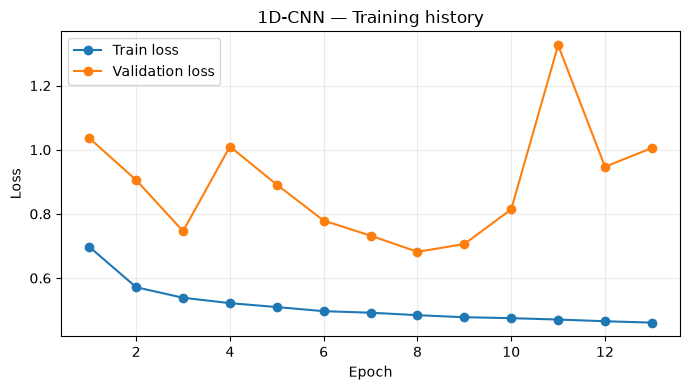

In [10]:
history_df = pd.read_csv(
    HISTORY_PATH
)

fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train loss",
)

ax.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation loss",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("1D-CNN — Training history")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

loss_path = FIGURES_DIR / "nb7_cnn_training_loss.png"
fig.savefig(
    loss_path,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(filename=str(loss_path))
)


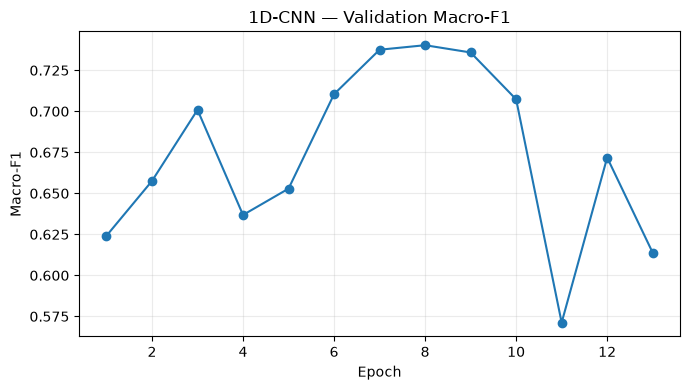

In [11]:
fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.plot(
    history_df["epoch"],
    history_df["val_f1_macro"],
    marker="o",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Macro-F1")
ax.set_title("1D-CNN — Validation Macro-F1")
ax.grid(alpha=0.25)

fig.tight_layout()

f1_path = FIGURES_DIR / "nb7_cnn_validation_f1.png"
fig.savefig(
    f1_path,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(filename=str(f1_path))
)


---
## 9. Evaluación final sobre el holdout

El test se evalúa una única vez utilizando el checkpoint con mejor Macro-F1 de validation.


In [12]:
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=DEVICE,
    )
)

model.eval()

test_true = []
test_pred = []

with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(
            DEVICE,
            non_blocking=True,
        )

        logits = model(x_batch)

        predictions = logits.argmax(
            dim=1
        ).cpu().numpy()

        test_true.extend(
            y_batch.numpy()
        )
        test_pred.extend(
            predictions
        )

test_true = np.asarray(
    test_true,
    dtype=np.int8,
)

test_pred = np.asarray(
    test_pred,
    dtype=np.int8,
)

holdout_metrics = {
    "model": "1D-CNN",
    "accuracy": float(
        accuracy_score(
            test_true,
            test_pred,
        )
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(
            test_true,
            test_pred,
        )
    ),
    "f1_macro": float(
        f1_score(
            test_true,
            test_pred,
            average="macro",
            zero_division=0,
        )
    ),
    "best_validation_f1_macro": float(
        best_val_f1
    ),
    "n_train_epochs": int(len(train_idx)),
    "n_validation_epochs": int(len(val_idx)),
    "n_test_epochs": int(len(test_idx)),
    "n_train_subjects": int(len(train_subjects)),
    "n_validation_subjects": int(len(val_subjects)),
    "n_test_subjects": int(len(test_subjects)),
}

display(
    pd.Series(
        holdout_metrics
    ).to_frame("value")
)

print(
    classification_report(
        test_true,
        test_pred,
        labels=STAGE_ORDER,
        target_names=STAGE_NAMES,
        digits=4,
        zero_division=0,
    )
)


,value
model,1D-CNN
accuracy,0.743692
balanced_accuracy,0.754138
f1_macro,0.735898
best_validation_f1_macro,0.740289
n_train_epochs,87307
n_validation_epochs,21532
n_test_epochs,26632
n_train_subjects,95
n_validation_subjects,24


              precision    recall  f1-score   support

           W     0.8787    0.7122    0.7868      4354
          N1     0.3734    0.6405    0.4718      3043
          N2     0.8624    0.6698    0.7540     10169
          N3     0.7874    0.8953    0.8379      5014
         REM     0.8065    0.8529    0.8291      4052

    accuracy                         0.7437     26632
   macro avg     0.7417    0.7541    0.7359     26632
weighted avg     0.7866    0.7437    0.7543     26632



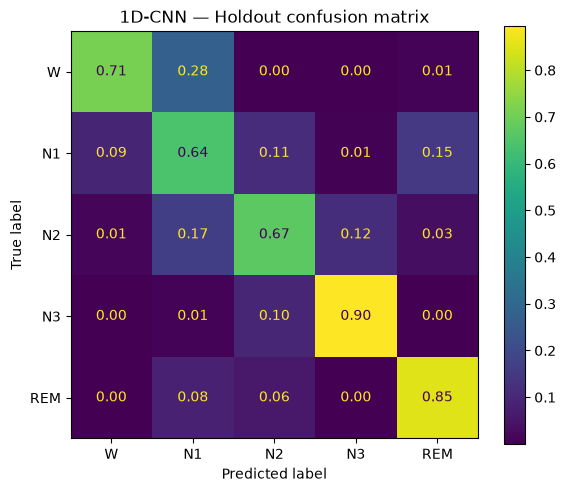

In [13]:
fig, ax = plt.subplots(
    figsize=(6, 5)
)

ConfusionMatrixDisplay.from_predictions(
    test_true,
    test_pred,
    labels=STAGE_ORDER,
    display_labels=STAGE_NAMES,
    normalize="true",
    values_format=".2f",
    ax=ax,
)

ax.set_title(
    "1D-CNN — Holdout confusion matrix"
)

fig.tight_layout()

cm_path = FIGURES_DIR / "nb7_cnn_confusion_matrix.png"
fig.savefig(
    cm_path,
    bbox_inches="tight",
)
plt.close(fig)

display(
    Image(filename=str(cm_path))
)


---
## 10. Guardado de resultados


In [14]:
prediction_cols = [
    "epoch_global",
    "subject",
    "source_epoch_index",
    "recording_onset_s",
    "qc_status",
    "qc_reason",
    "review_mask",
    "label",
]

predictions_df = metadata.loc[
    test_idx,
    prediction_cols,
].copy()

predictions_df = predictions_df.rename(
    columns={"label": "y_true"}
)

predictions_df["y_pred"] = test_pred

predictions_df.to_parquet(
    PREDICTIONS_PATH,
    index=False,
)

with open(
    METRICS_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        holdout_metrics,
        file,
        indent=2,
        ensure_ascii=False,
    )

print(
    f"Predicciones: {PREDICTIONS_PATH.resolve()}"
)
print(
    f"Métricas:     {METRICS_PATH.resolve()}"
)


Predicciones: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\dl_cnn_holdout_predictions.parquet
Métricas:     C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\dl_cnn_holdout_metrics.json


---
## 11. Checklist


In [15]:
checks = {
    "7 canales": signals.shape[1] == 7,
    "3000 muestras por epoch": signals.shape[2] == 3000,
    "Frecuencia 100 Hz": np.isclose(SFREQ, 100.0),
    "Señal en µV": SIGNAL_UNIT == "uV",
    "Train/validation sin solapamiento": train_subjects.isdisjoint(val_subjects),
    "Train/test sin solapamiento": train_subjects.isdisjoint(test_subjects),
    "Validation/test sin solapamiento": val_subjects.isdisjoint(test_subjects),
    "Test idéntico al de NB4": set(
        metadata.loc[test_idx, "subject"]
    ) == test_subjects,
    "Normalización calculada desde train": NORM_PATH.exists(),
    "Modelo guardado": MODEL_PATH.exists(),
    "Historial guardado": HISTORY_PATH.exists(),
    "Predicciones guardadas": PREDICTIONS_PATH.exists(),
    "Métricas guardadas": METRICS_PATH.exists(),
}

print("=" * 72)
print("CHECKLIST — 1D-CNN BASELINE")
print("=" * 72)

for label, passed in checks.items():
    print(
        f"{'✅' if passed else '❌'}  {label}"
    )

print()
print("Resultado final:")
print(
    f"  Accuracy:          {holdout_metrics['accuracy']:.4f}"
)
print(
    f"  Balanced accuracy: {holdout_metrics['balanced_accuracy']:.4f}"
)
print(
    f"  Macro-F1:          {holdout_metrics['f1_macro']:.4f}"
)

print()
print(
    "Próximo paso: incorporar contexto temporal entre epochs "
    "manteniendo la separación por sujeto."
)


CHECKLIST — 1D-CNN BASELINE
✅  7 canales
✅  3000 muestras por epoch
✅  Frecuencia 100 Hz
✅  Señal en µV
✅  Train/validation sin solapamiento
✅  Train/test sin solapamiento
✅  Validation/test sin solapamiento
✅  Test idéntico al de NB4
✅  Normalización calculada desde train
✅  Modelo guardado
✅  Historial guardado
✅  Predicciones guardadas
✅  Métricas guardadas

Resultado final:
  Accuracy:          0.7437
  Balanced accuracy: 0.7541
  Macro-F1:          0.7359

Próximo paso: incorporar contexto temporal entre epochs manteniendo la separación por sujeto.
